## Customer Churn Analysis Using Python

In [28]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
df=pd.read_csv("telco_churn.csv")
df

,Unnamed: 0,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,7590-VHVEG,Female,False,True,False,1,False,NaN,DSL,...,False,False,False,False,Month-to-month,True,Electronic check,29.850000,29.850000381469727,False
1,1,5575-GNVDE,Male,False,False,False,34,True,False,DSL,...,True,False,False,False,One year,False,Mailed check,56.950001,1889.5,False
2,2,3668-QPYBK,Male,False,False,False,2,True,False,DSL,...,False,False,False,False,Month-to-month,True,Mailed check,53.849998,108.1500015258789,True
3,3,7795-CFOCW,Male,False,False,False,45,False,NaN,DSL,...,True,True,False,False,One year,False,Bank transfer (automatic),42.299999,1840.75,False
4,4,9237-HQITU,Female,False,False,False,2,True,False,Fiber optic,...,False,False,False,False,Month-to-month,True,Electronic check,70.699997,151.64999389648438,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5038,2038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.800000,1990.5,No
5039,2039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.200000,7362.9,No
5040,2040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.600000,346.45,No
5041,2041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.400000,306.6,Yes


In [30]:
print(df.shape)

(5043, 22)


In [31]:
print(df.head())

   Unnamed: 0  customerID  gender SeniorCitizen Partner Dependents  tenure  \
0           0  7590-VHVEG  Female         False    True      False       1   
1           1  5575-GNVDE    Male         False   False      False      34   
2           2  3668-QPYBK    Male         False   False      False       2   
3           3  7795-CFOCW    Male         False   False      False      45   
4           4  9237-HQITU  Female         False   False      False       2   

  PhoneService MultipleLines InternetService  ... DeviceProtection  \
0        False           NaN             DSL  ...            False   
1         True         False             DSL  ...             True   
2         True         False             DSL  ...            False   
3        False           NaN             DSL  ...             True   
4         True         False     Fiber optic  ...            False   

  TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling  \
0       False       False       

In [32]:
print(df.columns)

Index(['Unnamed: 0', 'customerID', 'gender', 'SeniorCitizen', 'Partner',
       'Dependents', 'tenure', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges',
       'Churn'],
      dtype='str')


In [33]:
df['TotalCharges']=pd.to_numeric(df['TotalCharges'],errors='coerce')
df.isnull().sum()

Unnamed: 0            0
customerID            0
gender                0
SeniorCitizen         0
Partner               0
Dependents            0
tenure                0
PhoneService          0
MultipleLines       269
InternetService       0
OnlineSecurity      651
OnlineBackup        651
DeviceProtection    651
TechSupport         651
StreamingTV         651
StreamingMovies     651
Contract              0
PaperlessBilling      0
PaymentMethod         0
MonthlyCharges        0
TotalCharges          8
Churn                 1
dtype: int64

In [34]:
df=df.dropna()

In [35]:
print(df.head())

   Unnamed: 0  customerID  gender SeniorCitizen Partner Dependents  tenure  \
1           1  5575-GNVDE    Male         False   False      False      34   
2           2  3668-QPYBK    Male         False   False      False       2   
4           4  9237-HQITU  Female         False   False      False       2   
5           5  9305-CDSKC  Female         False   False      False       8   
6           6  1452-KIOVK    Male         False   False       True      22   

  PhoneService MultipleLines InternetService  ... DeviceProtection  \
1         True         False             DSL  ...             True   
2         True         False             DSL  ...            False   
4         True         False     Fiber optic  ...            False   
5         True          True     Fiber optic  ...             True   
6         True          True     Fiber optic  ...            False   

  TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling  \
1       False       False       

In [36]:
df['Churn'].unique()

<ArrowStringArray>
['False', 'True', 'No', 'Yes']
Length: 4, dtype: str

In [37]:
df['Churn'] = df['Churn'].apply(
    lambda x: 1 if str(x).strip().lower() in ['yes','true'] else 0
)

In [38]:
df

,Unnamed: 0,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
1,1,5575-GNVDE,Male,False,False,False,34,True,False,DSL,...,True,False,False,False,One year,False,Mailed check,56.950001,1889.500000,0
2,2,3668-QPYBK,Male,False,False,False,2,True,False,DSL,...,False,False,False,False,Month-to-month,True,Mailed check,53.849998,108.150002,1
4,4,9237-HQITU,Female,False,False,False,2,True,False,Fiber optic,...,False,False,False,False,Month-to-month,True,Electronic check,70.699997,151.649994,1
5,5,9305-CDSKC,Female,False,False,False,8,True,True,Fiber optic,...,True,False,True,True,Month-to-month,True,Electronic check,99.650002,820.500000,1
6,6,1452-KIOVK,Male,False,False,True,22,True,True,Fiber optic,...,False,False,True,False,Month-to-month,True,Credit card (automatic),89.099998,1949.400024,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5038,2038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.800000,1990.500000,0
5039,2039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.200000,7362.900000,0
5040,2040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.600000,346.450000,0
5041,2041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.400000,306.600000,1


In [39]:
df['Churn'].value_counts()

Churn
0    2886
1    1232
Name: count, dtype: int64

In [40]:
#visualization of churn

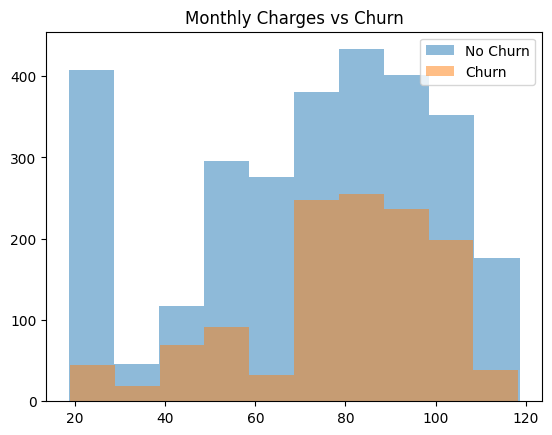

In [41]:
plt.hist(df[df['Churn']==0]['MonthlyCharges'], alpha=0.5, label='No Churn')
plt.hist(df[df['Churn']==1]['MonthlyCharges'], alpha=0.5, label='Churn')
plt.legend()
plt.title("Monthly Charges vs Churn")
plt.show()

Histogram analysis shows that customers with higher monthly charges exhibit a higher tendency to churn.<br> However, significant overlap between churned and retained customers suggests that churn depends on multiple factors such as tenure, contract type, and service features.

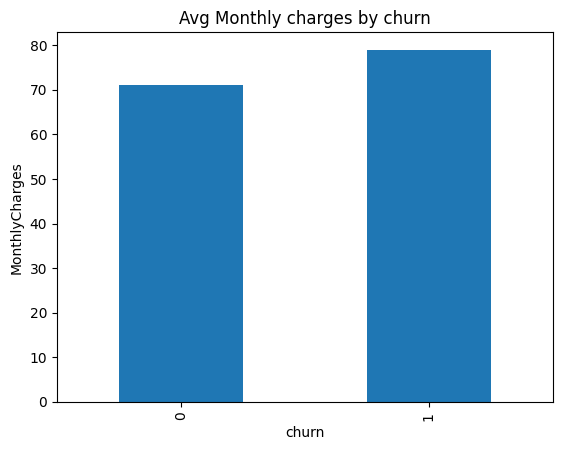

In [42]:
df.groupby('Churn')['MonthlyCharges'].mean().plot(kind='bar')
plt.xlabel('churn')
plt.ylabel('MonthlyCharges')
plt.title("Avg Monthly charges by churn")
plt.show()

Customers with higher monthly charges show a greater tendency to churn,<br>
indicating pricing sensitivity and potential dissatisfaction with service cost.

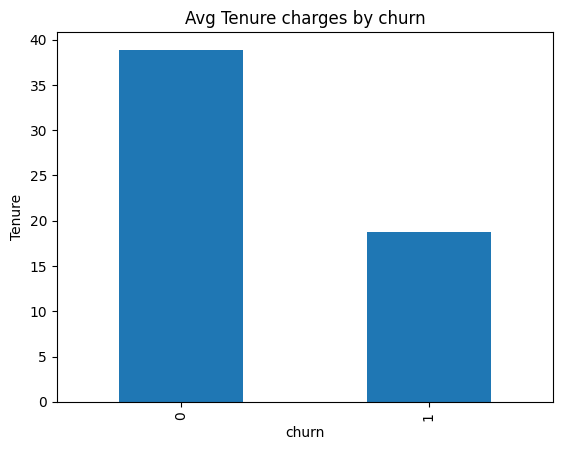

In [43]:
df.groupby('Churn')['tenure'].mean().plot(kind='bar')
plt.xlabel('churn')
plt.ylabel('Tenure')
plt.title("Avg Tenure charges by churn")
plt.show()

Customers with shorter tenure are significantly more likely to churn, whereas on the other hand customers with high tenure have very less chances of churning; <br>  Suggesting that early customer engagement and retention strategies are crucial.

In [44]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X_full = pd.get_dummies(
    df.drop(columns=['customerID', 'Churn', 'Unnamed: 0']), drop_first=True
)
y_full = df['Churn']

Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42, stratify=y_full
)

model = LogisticRegression(max_iter=1000)
model.fit(Xf_train, yf_train)

c:\Users\Apurva Malankar\exam_env\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [45]:
prediction=model.predict(Xf_test)
print("Prediction:", prediction)

Accuracy= accuracy_score(yf_test, prediction)
print("\nAccuracy:", Accuracy)

Prediction: [0 1 0 0 0 0 0 1 0 0 0 1 1 1 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 1 1
 0 1 0 0 1 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 1 0 0 0 1 0 1 1 1 0 0 0 1 0 0
 0 0 0 0 1 1 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 0 0 0
 0 1 0 0 1 0 1 0 1 1 1 1 1 1 0 1 0 0 0 1 1 0 0 1 0 1 0 1 1 0 0 0 0 0 1 1 0
 0 0 1 0 0 0 1 1 1 0 1 1 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 1 0 0 0 0 1 0 0
 1 0 0 0 1 0 0 1 0 1 0 1 1 0 0 1 0 0 0 1 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 1 1 0 0 1 1 0 0 0 0 0 1 1 0 0 0 1 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 1 0 0 1 0 1 1 1 0 0 0 0 0 0 0
 0 0 1 0 0 0 1 0 1 0 0 1 0 0 0 0 1 0 0 0 0 1 0 1 0 0 0 0 0 0 1 1 0 0 0 0 0
 0 1 0 1 0 1 1 1 1 0 1 0 1 0 0 1 0 0 1 0 0 0 0 0 1 0 0 1 0 0 1 0 0 1 0 0 1
 0 0 0 0 0 0 1 1 0 0 0 0 1 1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 1 0 1 0 1 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 1 1 1 1 0 0 1 0 0 0 1 1 0 0 1
 0 0 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 1 0 1 0 0 1 0 0
 1 0 1 1 1 0 

In [46]:
from sklearn.metrics import classification_report

print(classification_report(yf_test, prediction))

              precision    recall  f1-score   support

           0       0.83      0.87      0.85       577
           1       0.65      0.57      0.61       247

    accuracy                           0.78       824
   macro avg       0.74      0.72      0.73       824
weighted avg       0.77      0.78      0.78       824



In [47]:
model_bal = LogisticRegression(max_iter=1000, class_weight='balanced')
model_bal.fit(Xf_train, yf_train)

c:\Users\Apurva Malankar\exam_env\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

In [48]:
print(classification_report(yf_test, model_bal.predict(Xf_test)))

              precision    recall  f1-score   support

           0       0.88      0.71      0.79       577
           1       0.53      0.78      0.63       247

    accuracy                           0.73       824
   macro avg       0.71      0.74      0.71       824
weighted avg       0.78      0.73      0.74       824



In [49]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                            class_weight='balanced', random_state=42)
rf.fit(Xf_train, yf_train)

print(classification_report(yf_test, rf.predict(Xf_test)))

              precision    recall  f1-score   support

           0       0.87      0.80      0.83       577
           1       0.60      0.72      0.66       247

    accuracy                           0.77       824
   macro avg       0.74      0.76      0.74       824
weighted avg       0.79      0.77      0.78       824



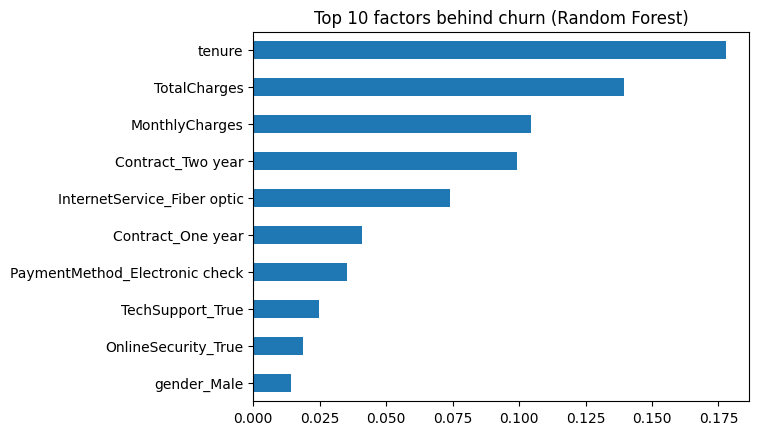

In [50]:
imp = pd.Series(rf.feature_importances_, index=Xf_train.columns).sort_values(ascending=False)
imp.head(10).plot(kind='barh').invert_yaxis()
plt.title("Top 10 factors behind churn (Random Forest)")
plt.show()

#### Model Selection and Comparison

**Objective:** Identify customers likely to churn so that retention efforts can be targeted.

Approximately 30% of customers in this dataset churn. A model that predicts "no churn" for most customers can therefore achieve high accuracy while failing to identify the customers of interest. Models are evaluated primarily on precision, recall and F1-score for the churn class.

**Models compared**

| Model | Rationale |
|---|---|
| Logistic Regression | Interpretable baseline; coefficients show the direction of each feature's effect. |
| Logistic Regression (class-balanced) | Same model with higher weight on churners during training, aimed at improving recall. |
| Random Forest (class-balanced) | Captures non-linear relationships and feature interactions; provides feature importance. |

**Relevance to the business problem:** Higher recall identifies more at-risk customers but increases false alarms, since more loyal customers receive retention offers. Comparing the models quantifies this trade-off and supports a model choice based on the relative cost of a missed churner versus an unnecessary offer.

In [51]:
df.groupby('Contract')['Churn'].mean()

Contract
Month-to-month    0.458211
One year          0.132231
Two year          0.032584
Name: Churn, dtype: float64

In [52]:
df.groupby('InternetService')['Churn'].mean()

InternetService
DSL            0.169092
Fiber optic    0.423231
No             0.086449
Name: Churn, dtype: float64

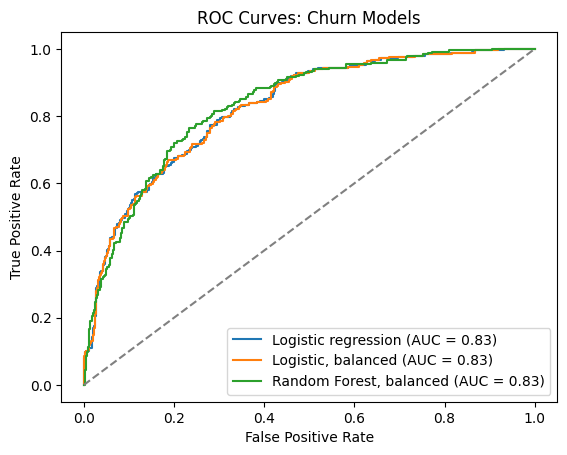

In [53]:
from sklearn.metrics import roc_curve, auc

models = {
    "Logistic regression": model,
    "Logistic, balanced": model_bal,
    "Random Forest, balanced": rf,
}

for name, m in models.items():
    prob = m.predict_proba(Xf_test)[:, 1]
    fpr, tpr, _ = roc_curve(yf_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.2f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves: Churn Models")
plt.legend()
plt.show()

All three models reach a ROC-AUC of about 0.83, which indicates good ability to separate churners from non-churners, and they rank customers almost equally well. <br> 
The differences between them come from where each draws the line: the balanced models catch more churners (recall 0.72 to 0.78) <br>
but flag more customers who would have stayed (lower precision). <br>
The choice of model therefore depends on whether missing a churner or sending an unnecessary retention offer costs more.